# El Niño: how far ahead depends on the month you ask

**Averaged over every month of 56 years, a regression on the Southern Oscillation Index beats the long-run average for seven months ahead. Split by the month the forecast is made, that number falls apart. A forecast that has to pass from April into May gains nothing, not even one month ahead. One that does not is still ahead nine months out. The limit is a date on the calendar, not a number of months.**

"How far ahead is this forecast worth anything?" sounds like a question with one answer, and a backtest will happily give one. This notebook gets that answer, then asks the kept run a second question, finds that the first answer was an average of two very different situations, and checks that the difference is not luck.

*Data: the Southern Oscillation Index for every month from 1900 to 2005, from the R package DAAG, which took it from the Australian Bureau of Meteorology ([source and license](data/README.md#southern-oscillation)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.linear_model import LinearRegression

from timegym import LastValueForecaster, NaiveForecaster, Pipeline, Scenario, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

The Southern Oscillation Index compares the air pressure at Tahiti with the air pressure at Darwin, month by month. When it stays well below zero for months, the Pacific is in an El Niño, which in eastern Australia tends to mean a dry year. When it stays well above zero, it is a La Niña, and the odds shift to a wet one. Farmers, water managers and insurers would like to know the index some months ahead. The job is to forecast the next nine months, and to know how many of those nine forecasts are worth acting on.

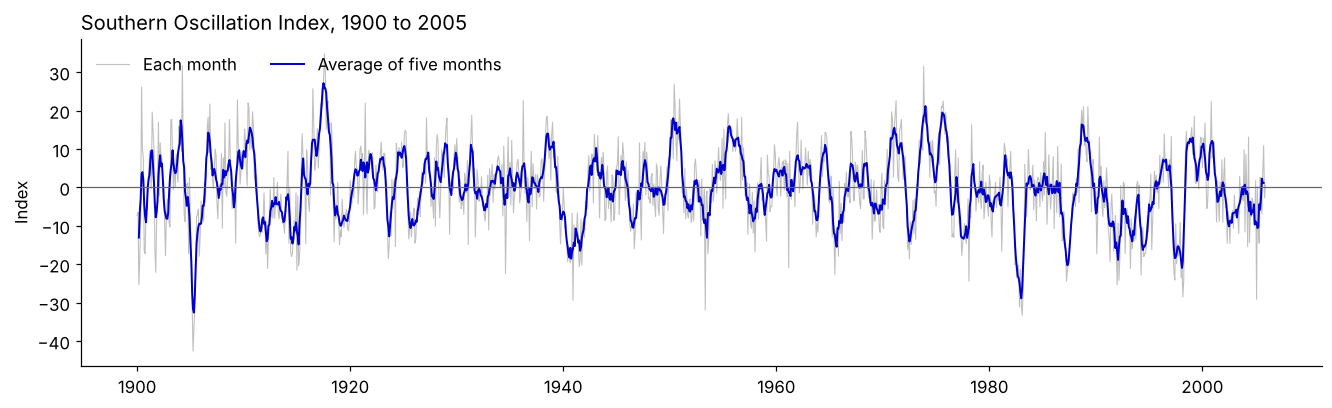

1,272 months, January 1900 to December 2005.
Long-run average: -0.1. A typical month is 8.2 away from zero.
Lowest five-month average: -32.6, around May 1905.
Highest five-month average: +27.2, around July 1917.


In [2]:
soi = load("southern-oscillation")
index = soi["soi"]
smooth = index.rolling(5, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
when = index.index.to_timestamp()
ax.plot(when, index, color="0.75", linewidth=0.7, label="Each month")
ax.plot(when, smooth, color="#0000CC", linewidth=1.3, label="Average of five months")
ax.axhline(0, color="0.4", linewidth=0.8)
ax.set(title="Southern Oscillation Index, 1900 to 2005", ylabel="Index")
ax.legend(ncols=2, loc="upper left")
plt.show()

print(f"{len(index):,} months, {index.index[0]:%B %Y} to {index.index[-1]:%B %Y}.")
print(f"Long-run average: {index.mean():+.1f}. A typical month is {index.abs().mean():.1f} away from zero.")
print(f"Lowest five-month average: {smooth.min():.1f}, around {smooth.idxmin():%B %Y}.")
print(f"Highest five-month average: {smooth.max():+.1f}, around {smooth.idxmax():%B %Y}.")
assert len(index) == 1272 and abs(index.mean()) < 0.2

The single months jump around. The five-month average shows the slow swings underneath, which last a year or so and are what a forecast can hope to catch.

## How far ahead, on average?

A forecast is made at the end of every month from December 1949 to March 2005, each time for the next nine months: 664 cases, each with at least fifty years of history. Three forecasters, all from TimeGym or through it:

- **Long-run average** forecasts the average of everything so far, which is close to zero. It knows nothing about the present, so it is the forecaster to beat: any other is worth its *gain*, the share by which it misses less.
- **Same as last month** repeats the latest value for all nine months.
- **Regression on the last 3 months** is a scikit-learn linear regression. `reduction="multioutput"` fits it from the last three months to all nine months ahead at once.

The run keeps every forecast and every answer, so the miss can be counted separately for each month ahead.

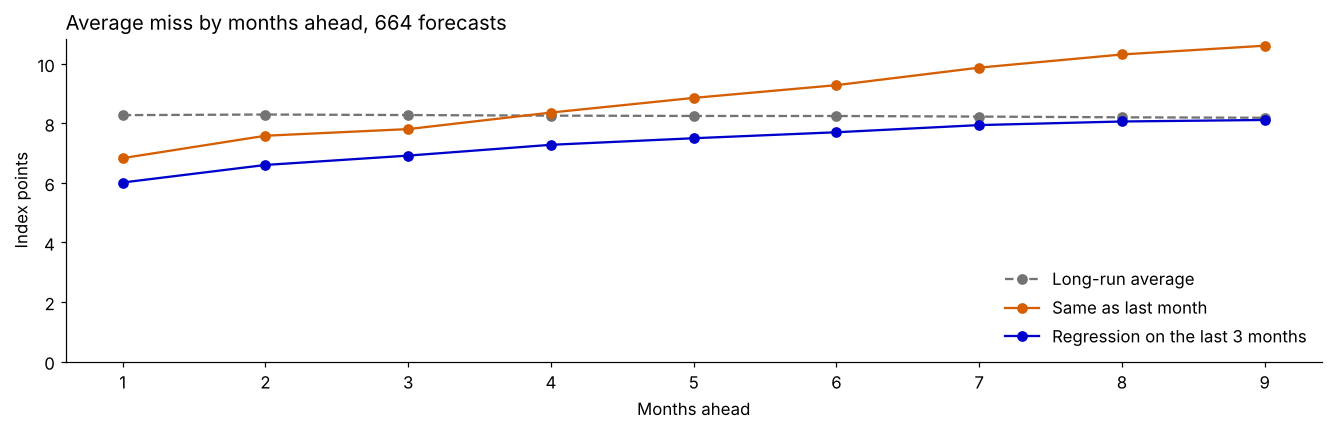

Regression against the long-run average, by months ahead:
  Months ahead   Gain   Miss lower by (95% interval)
       1          27%   2.26  (+1.84 to +2.69)
       2          20%   1.69  (+1.32 to +2.07)
       3          16%   1.36  (+1.03 to +1.69)
       4          12%   0.98  (+0.68 to +1.28)
       5           9%   0.75  (+0.48 to +1.02)
       6           7%   0.55  (+0.31 to +0.78)
       7           3%   0.29  (+0.10 to +0.47)
       8           2%   0.14  (-0.01 to +0.29)
       9           1%   0.07  (-0.05 to +0.20)


In [3]:
HORIZON = 9
TEST = range(12 * 50, len(soi) - HORIZON + 1)       # rows of history: forecasts made December 1949 to March 2005


def step_misses(pipeline, cases):
    "Run a forecaster; return its miss at every step, one row per case and one column per month ahead."
    run = pipeline.run(cases=cases)
    counts = run.report.summary["status_counts"]
    assert counts["FAIL"] == 0 and counts["ERROR"] == 0, counts
    forecast = np.array([entry.forecast.point[:, 0] for entry in run.cases])
    came = np.array([entry.case.observed.to_numpy()[:, 0] for entry in run.cases])
    return np.abs(forecast - came)


def average_and_regression(table, origins, name):
    "Cut the cases, and return the month each forecast was made in and the two forecasters' misses."
    cases = cases_from_series(table, origins=origins, horizon=HORIZON, name=name)
    asked = np.array([pd.Period(case.manifest["origin"]).month for case in cases])
    average = step_misses(Pipeline(NaiveForecaster("mean")), cases)
    regression = step_misses(Pipeline(LinearRegression(), window_length=3, reduction="multioutput"), cases)
    return asked, average, regression


asked, average, regression = average_and_regression(soi, TEST, "soi")
cases = cases_from_series(soi, origins=TEST, horizon=HORIZON, name="soi")
last_month = step_misses(Pipeline(LastValueForecaster()), cases)
ahead = np.arange(1, HORIZON + 1)

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
ax.plot(ahead, average.mean(axis=0), color="0.45", linestyle="--", marker="o", label="Long-run average")
ax.plot(ahead, last_month.mean(axis=0), color="#D55E00", marker="o", label="Same as last month")
ax.plot(ahead, regression.mean(axis=0), color="#0000CC", marker="o", label="Regression on the last 3 months")
ax.set(title=f"Average miss by months ahead, {len(cases)} forecasts", xlabel="Months ahead", ylabel="Index points",
       ylim=(0, None))
ax.legend(loc="lower right")
plt.show()

print("Regression against the long-run average, by months ahead:")
print("  Months ahead   Gain   Miss lower by (95% interval)")
clear = []
for month in ahead:
    gap = paired_t_interval(average[:, month - 1] - regression[:, month - 1])
    gain = 100 * gap["mean"] / average[:, month - 1].mean()
    clear.append(gap["ci95"][0] > 0)
    print(f"  {month:^12d}  {gain:4.0f}%   {gap['mean']:.2f}  ({gap['ci95'][0]:+.2f} to {gap['ci95'][1]:+.2f})")

overall = [round(gain_) for gain_ in 100 * (1 - regression.mean(axis=0) / average.mean(axis=0))]
assert len(cases) == 664 and clear == [True] * 7 + [False] * 2 and overall[0] == 27 and overall[5] == 7
assert (last_month.mean(axis=0) > average.mean(axis=0)).tolist() == [False] * 3 + [True] * 6

"Same as last month" is ahead of the long-run average for three months and then worse than knowing nothing: by then the index has usually drifted back toward zero, and that forecast has not. The regression allows for the drift. It is 27% better than the long-run average one month ahead and 7% better at six months, and its lead is clear of zero through the seventh month.

So: seven months. That is the answer a backtest gives. It is an average over forecasts made in every month of the year.

## Ask again, by month

The kept run can answer a sharper question. Every case's manifest records where its history ends, so the 664 forecasts can be sorted by the month they were made in. That gives twelve groups of 55 or 56 forecasts, and the gain can be worked out for each group at each month ahead.

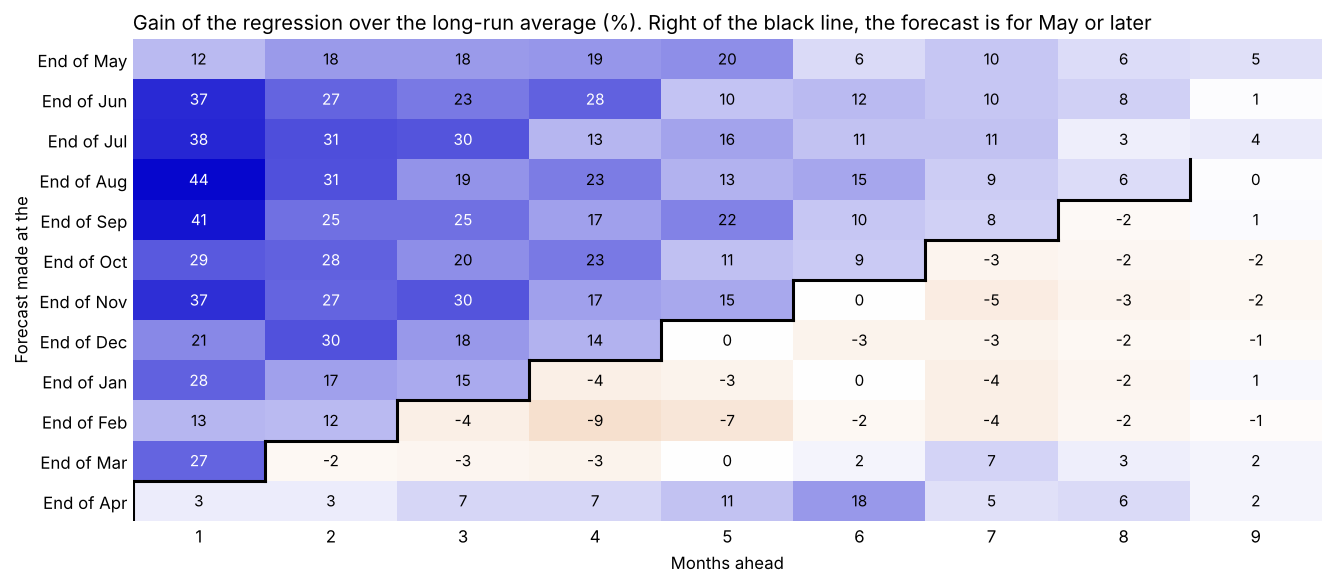

Each cell is the average over 56 or 55 forecasts.


In [4]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def gain(average, model, where=slice(None)):
    "The share by which a forecaster misses less than the long-run average, in percent."
    return 100 * (1 - model[where].mean() / average[where].mean())


by_month = pd.DataFrame([[gain(average[:, step], regression[:, step], asked == month) for step in range(HORIZON)]
                         for month in range(1, 13)], index=MONTHS, columns=ahead)
order = MONTHS[4:] + MONTHS[:4]                       # start the rows at May

fig, ax = plt.subplots(figsize=(12, 5.2), layout="constrained")
colors = LinearSegmentedColormap.from_list("gain", ["#D55E00", "white", "#0000CC"])
ax.imshow(by_month.loc[order], cmap=colors, norm=TwoSlopeNorm(vmin=-45, vcenter=0, vmax=45), aspect="auto")
for row, month in enumerate(order):
    for column in range(HORIZON):
        value = by_month.loc[month, column + 1]
        ax.text(column, row, str(int(round(float(value)))), ha="center", va="center", fontsize=10,
                color="white" if value > 25 else "black")
    reach = (4 - MONTHS.index(month) - 1) % 12        # months ahead that stay on this side of the end of April
    if reach < HORIZON:
        ax.plot([reach - 0.5, reach - 0.5], [row - 0.5, row + 0.5], color="black", linewidth=2)
        if reach:
            ax.plot([reach - 1.5, reach - 0.5], [row + 0.5, row + 0.5], color="black", linewidth=2)
ax.set_xticks(range(HORIZON), ahead)
ax.set_yticks(range(12), [f"End of {month}" for month in order])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set(title="Gain of the regression over the long-run average (%). Right of the black line, the forecast is for May or later",
       xlabel="Months ahead", ylabel="Forecast made at the")
plt.show()

per_month = int((asked == 1).sum())
print(f"Each cell is the average over {per_month} or {int((asked == 4).sum())} forecasts.")
assert by_month.loc[["Jun", "Jul", "Aug"], 6].min() > 10 and abs(by_month.loc["Apr", 1]) < 5
assert by_month.loc["Feb", :2].min() > 10 and by_month.loc["Feb", 3:].max() < 0
assert by_month.loc["Mar", 1] > 20 and by_month.loc["Mar", 2] < 0
assert by_month.loc["Apr", [5, 6]].round().tolist() == [11, 18]

This is not one horizon. Made at the end of June, July or August, the forecast still gains more than 10% six months ahead. Made at the end of February it gains for two months, and at the end of March for one. And the edge of the blue area is a staircase: one row down, one step to the left. A staircase like that means the edge sits at a fixed place on the calendar. The black line marks where the month being forecast becomes May, and the gains stop at that line.

One row fits less neatly. A forecast made at the end of April has almost nothing to say about May, and then gains 11% and 18% for September and October. Each cell is an average over 55 or 56 forecasts, so no single cell should be leaned on. That is a warning about the whole picture too: a pattern found by looking at a table can be a pattern of luck.

## Is April special?

Two checks, each with something the picture did not use.

**Earlier years.** The picture used forecasts made from 1950 on. The same split can be made for forecasts made from 1920 to 1949, which share no forecast with them. For each month of the year, take the forecasts that have to pass the end of that month to reach the month they are for, take the ones that do not, and compare the two gains. If April matters, the difference should be largest for April in both periods.

**A series with no seasons.** TimeGym can generate a series with a chosen amount of memory. Here that is a slow part that fades a little each month plus month-to-month noise, both sized from the index's first fifty years. The generated series gets the index's calendar, but nothing in it knows what month it is. Any difference it shows between months is luck, and five such series give an idea of how large luck gets.

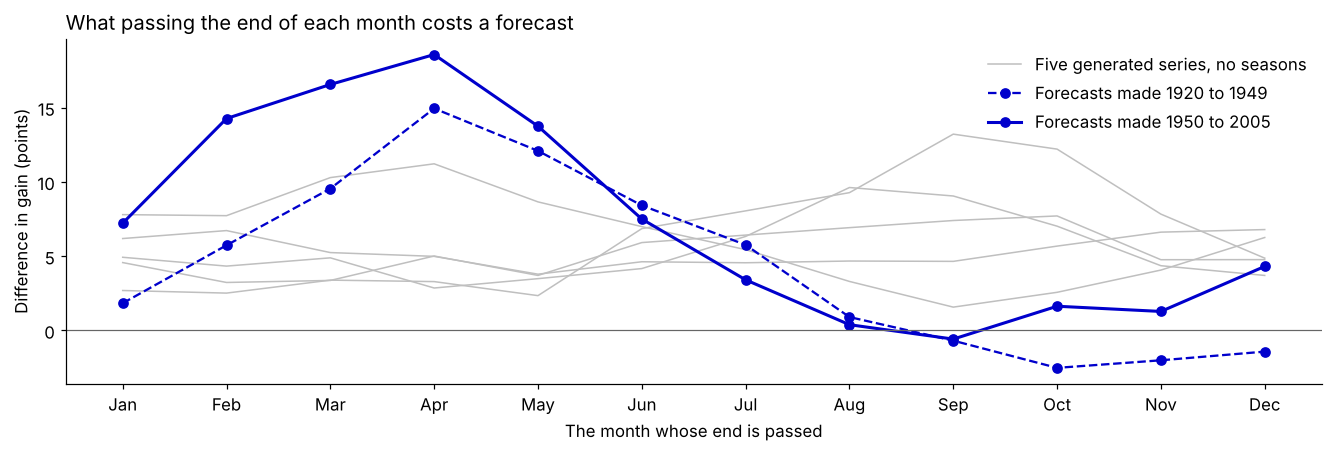

1920 to 1949: the largest difference is at the end of Apr (14.9 points).
1950 to 2005: the largest difference is at the end of Apr (18.6 points).
Generated series: the largest differences are 6.8 to 13.2 points,
  at the end of Aug, Dec, Apr, Sep, Oct.


In [5]:
def crosses(asked, after):
    "True where a forecast must pass from month `after` into the next month to reach the month it is for."
    wait = (after - asked) % 12
    return wait[:, None] < ahead[None, :]


def difference(asked, average, model):
    "For each month of the year: gain of forecasts that do not pass its end, minus gain of those that do."
    return pd.Series([gain(average, model, ~crosses(asked, after)) - gain(average, model, crosses(asked, after))
                      for after in range(1, 13)], index=MONTHS)


EARLIER = range(12 * 20, 12 * 50 - HORIZON + 1)       # forecasts made December 1919 to March 1949
earlier = difference(*average_and_regression(soi, EARLIER, "soi"))
later = difference(asked, average, regression)

# A generated series with the index's memory and no seasons: a slow part that fades, plus month-to-month noise,
# sized from the index's first fifty years.
first_fifty = index.iloc[: 12 * 50].to_numpy()
link = lambda months: np.corrcoef(first_fifty[:-months], first_fifty[months:])[0, 1]
phi = (link(6) / link(1)) ** (1 / 5)
share = link(1) / phi
memory = {"phi": phi, "sigma": np.sqrt(first_fifty.var() * share * (1 - phi ** 2)),
          "noise": np.sqrt(first_fifty.var() * (1 - share))}


def generated(seed):
    case = Scenario("ar1", context_length=len(soi) - HORIZON, horizon=HORIZON, parameters=memory, seed=seed).generate()
    values = pd.concat([case.task.context, case.observed]).to_numpy()[:, 0]
    return pd.DataFrame({"soi": values}, index=soi.index)


controls = pd.DataFrame({seed: difference(*average_and_regression(generated(seed), TEST, "generated")) for seed in range(1, 6)})

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
for seed in controls:
    ax.plot(MONTHS, controls[seed], color="0.75", linewidth=1, label="Five generated series, no seasons" if seed == 1 else None)
ax.plot(MONTHS, earlier, color="#0000CC", linestyle="--", marker="o", label="Forecasts made 1920 to 1949")
ax.plot(MONTHS, later, color="#0000CC", marker="o", linewidth=2, label="Forecasts made 1950 to 2005")
ax.axhline(0, color="0.4", linewidth=0.8)
ax.set(title="What passing the end of each month costs a forecast",
       xlabel="The month whose end is passed", ylabel="Difference in gain (points)")
ax.legend(loc="upper right")
plt.show()

print(f"1920 to 1949: the largest difference is at the end of {earlier.idxmax()} ({earlier.max():.1f} points).")
print(f"1950 to 2005: the largest difference is at the end of {later.idxmax()} ({later.max():.1f} points).")
print(f"Generated series: the largest differences are {controls.max().min():.1f} to {controls.max().max():.1f} points,")
print(f"  at the end of {', '.join(controls.idxmax())}.")
assert earlier.idxmax() == later.idxmax() == "Apr" and min(earlier.max(), later.max()) > controls.max().max()
assert [round(earlier.max(), 1), round(later.max(), 1)] == [14.9, 18.6] and controls.idxmax().is_unique
assert 6.5 < controls.max().min() and controls.max().max() < 13.5

In both periods the difference is largest at the end of April: 14.9 points in the earlier years and 18.6 in the later ones. The five generated series reach between 7 and 13 points, each at a different month. Luck does produce a difference of some size. It did not reach either of the real ones, and it has no reason to pick the same month twice.

## The same month ahead, two answers

With April pointed to by years the test does not use, go back to the 664 test forecasts and split each month ahead in two: the forecasts that stay on one side of the end of April, and the ones that have to pass it.

              Stays on one side of April    Passes from April into May
Months ahead  Forecasts  Gain  Clear of 0   Forecasts  Gain  Clear of 0
     1           609      30%     yes          55        3%      no
     2           553      24%     yes          111       1%      no
     3           497      22%     yes          167       0%      no
     4           441      19%     yes          223      -2%      no
     5           385      16%     yes          279       0%      no
     6           330      11%     yes          334       2%      no
     7           275      10%     yes          389      -1%      no
     8           220       6%     yes          444      -1%      no
     9           165       3%     yes          499       0%      no


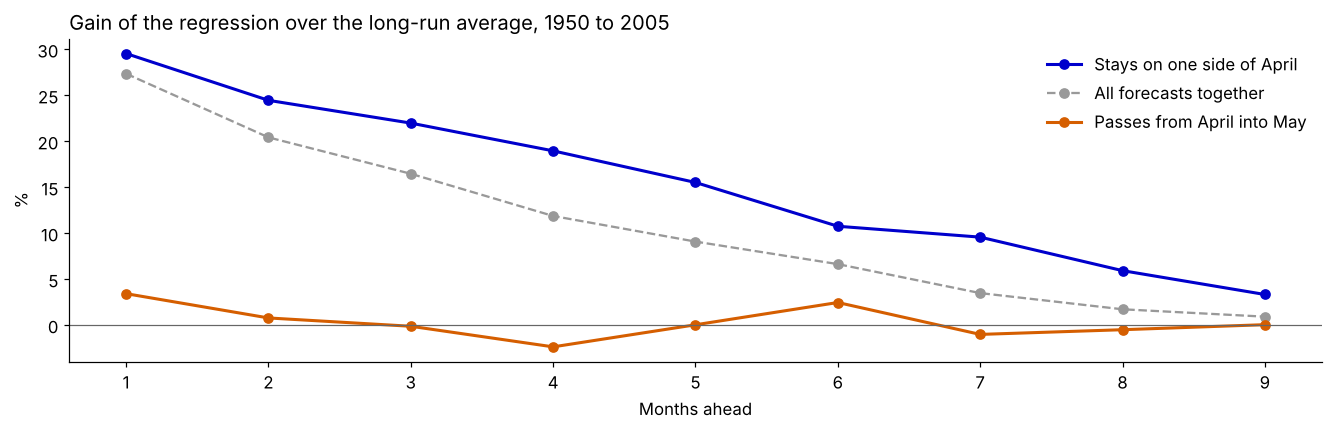

All nine months ahead together:
  18.5% for forecasts that stay on one side of April,
  0.0% for forecasts that pass from April into May.


In [6]:
passes_april = crosses(asked, 4)
lines = {"Stays on one side of April": [], "Passes from April into May": []}
print("              Stays on one side of April    Passes from April into May")
print("Months ahead  Forecasts  Gain  Clear of 0   Forecasts  Gain  Clear of 0")
settled = {name: [] for name in lines}
for step, month in enumerate(ahead):
    row = f"{month:^12d}"
    for name, chosen in (("Stays on one side of April", ~passes_april[:, step]), ("Passes from April into May", passes_april[:, step])):
        gap = paired_t_interval(average[chosen, step] - regression[chosen, step])
        lines[name].append(gain(average[:, step], regression[:, step], chosen))
        settled[name].append(gap["ci95"][0] > 0)
        row += f"  {chosen.sum():^9d} {round(lines[name][-1]):4d}%  {'yes' if settled[name][-1] else 'no':^10s} "
    print(row.rstrip())

fig, ax = plt.subplots(figsize=(12, 3.8), layout="constrained")
ax.plot(ahead, lines["Stays on one side of April"], color="#0000CC", marker="o", linewidth=2, label="Stays on one side of April")
ax.plot(ahead, [gain(average[:, step], regression[:, step]) for step in range(HORIZON)], color="0.6", linestyle="--",
        marker="o", label="All forecasts together")
ax.plot(ahead, lines["Passes from April into May"], color="#D55E00", marker="o", linewidth=2, label="Passes from April into May")
ax.axhline(0, color="0.4", linewidth=0.8)
ax.set(title="Gain of the regression over the long-run average, 1950 to 2005", xlabel="Months ahead", ylabel="%")
ax.legend(loc="upper right")
plt.show()

stays, passes = gain(average, regression, ~passes_april), gain(average, regression, passes_april)
print("All nine months ahead together:")
print(f"  {stays:.1f}% for forecasts that stay on one side of April,")
print(f"  {abs(passes):.1f}% for forecasts that pass from April into May.")
assert all(settled["Stays on one side of April"]) and not any(settled["Passes from April into May"])
assert round(stays, 1) == 18.5 and abs(passes) < 0.05
assert round(lines["Stays on one side of April"][0]) == 30 and round(lines["Stays on one side of April"][-1]) == 3
assert passes_april[:, 0].sum() == 55

The two groups hardly resemble each other. A forecast that stays on one side of April gains 30% one month ahead and is still 3% ahead at nine months, clear of zero at every step. A forecast that passes from April into May gains nothing at any step, and that includes the 55 forecasts made at the end of April for the very next month. "Seven months" was an average of the two, weighted by how many forecasts of each kind there happened to be at each step.

So the answer to "how far ahead?" is a rule, not a number: **until April**. A forecast made at the end of June is worth using into the new year. One made at the end of January is worth three months. One made at the end of April is worth waiting a month for.

Climate forecasters know this as the spring predictability barrier, the spring being the northern hemisphere's. El Niño and La Niña tend to start around the middle of the year and fade early in the next, so what the index did before April says little about what it does after. This notebook did not need to know that beforehand. It needed the forecasts kept case by case, and the month each one was made in.

## What TimeGym added

- **Three forecasters in three lines.** The long-run average and "same as last month" are built in, and a scikit-learn regression became a nine-month forecaster with `window_length=3, reduction="multioutput"`.
- **Every step of every case, kept.** The miss could be counted by months ahead. Each case's manifest says where its history ends, so it could also be counted by the month the forecast was made in. The staircase was already in the first run; it took a second question to see it.
- **A paired interval for each claim.** "Clear of zero through seven months" and "not clear at any step" both come from `paired_t_interval` on the same cases.
- **A generated series as a yardstick for luck.** `Scenario("ar1", ...)` with measurement noise gave series with the index's memory and no seasons, and the same code ran on them.

## Change one thing

- Make the forecaster aware of the calendar, with one regression for each month of the year. Each gets a twelfth of the data. Does it stop forecasting past April, and does it gain anything before it?
- Look further with `HORIZON = 12`. Does a forecast made at the end of May still gain for the following April?
- Use a longer look-back, `window_length=6` or `12`. Does anything get across April?
- The forecasts made from 1920 to 1949 are already cut. Draw their staircase. Is it as sharp?

**What this doesn't show.** One index and one simple regression. Weather services forecast El Niño from ocean temperatures, including those below the surface, and may see further across April than this index's own past does. The index is not rainfall: it shifts the odds of a wet or dry year and settles nothing for one farm. Forecasts made a month apart share most of their nine months, which makes the intervals too narrow; the earlier years and the generated series are the stronger evidence. Five generated series give a rough idea of how large luck gets, not its exact odds.

**Related:** [The sunspot cycle](sunspots.ipynb) asks how far ahead a forecast is worth making for a slower cycle, [Reductions](../tutorials/05_reductions.ipynb) explains the ways a regression forecasts several steps ahead, and [Call center staffing](call-center.ipynb) is another job where the time a forecast is made decides what it is worth. More examples are on the [examples page](../docs/examples.md).